# Ecobici — 04. Simulación y comparación de estrategias (Etapa 4)

1. Un simulador Monte Carlo de la subred completa, con el camión.
2. Validación del simulador: contra Kolmogorov y contra los viajes observados.
3. Escenarios de demanda a partir de los 13 meses.
4. Evaluación de la estrategia asignada (política actual de Ecobici) y de la propuesta en cada escenario.
5. Comparación con los criterios de decisión: valor esperado, Laplace, Wald, Hurwicz y Savage.

Hay que correr antes `modelo.ipynb` (λ, μ y lotes) y `camion.ipynb` (política actual, propuesta y arranques).

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DIR_TABLAS, DIR_FIG = Path("outputs/tablas"), Path("outputs/figuras")
SUBRED = {"271-272": "Buenavista", "273-274": "Buenavista", "014": "Reforma", "027": "Reforma", "018": "Reforma"}
ORDEN, HORAS = list(SUBRED), np.arange(5, 24)
COLORES = {"Buenavista": "#d1495b", "Reforma": "#2e86ab"}

# Parámetros (modelo.ipynb)
tasas = pd.read_csv(DIR_TABLAS / "tasas_modelo.csv", dtype={"estacion": str})
B = pd.read_csv(DIR_TABLAS / "lotes.csv", dtype={"estacion": str}).set_index(["estacion", "proceso"]).b
DOCKS = tasas.groupby("estacion").docks.first().astype(int)
LAM = {e: tasas[(tasas.estacion == e) & (tasas.proceso == "devolucion")].set_index("hora").tasa.reindex(HORAS).fillna(0).to_numpy() for e in ORDEN}
MU = {e: tasas[(tasas.estacion == e) & (tasas.proceso == "retiro")].set_index("hora").tasa.reindex(HORAS).fillna(0).to_numpy() for e in ORDEN}

# Políticas (camion.ipynb)
pol = pd.read_csv(DIR_TABLAS / "camion_politicas.csv", dtype={"estación": str}).set_index(["política", "estación"])
visitas = pd.read_csv(DIR_TABLAS / "camion_propuesta.csv", dtype={"estación": str})
cam_h = pd.read_csv(DIR_TABLAS / "camion_actual_hora.csv", dtype={"estacion": str}).set_index(["tipo", "estacion"])
cam_h.columns = cam_h.columns.astype(int)
NETO_ACTUAL = cam_h.loc["deja"] - cam_h.loc["saca"]          # bicis netas por hora que deja hoy el camión

## 1. Simulador

Se simula un día evento por evento (algoritmo de Gillespie), con el mismo modelo de las etapas 2 y 3:

- En cada hora los lotes de devoluciones y de retiros llegan con tasa $\lambda(h)/b$ y $\mu(h)/b$. El tiempo al siguiente lote es exponencial y su tamaño es geométrico de media $b$. Si no cabe o no hay bici, se cuenta un rechazo.
- El camión actúa en sus horarios:
  - política actual: el neto promedio de cada hora, cada 5 min;
  - propuesta: deja la estación con $y$ bicis;
  - propuesta con camión de 40: igual, pero moviendo a lo más 40 bicis por visita.
- Lo nuevo frente a Kolmogorov es la variación entre días. Cada día simulado se sortea un factor $G$ (gamma de media 1) por estación y proceso, que multiplica sus tasas. Así un día puede tener más o menos demanda que el promedio, que era el supuesto 4 que no se cumplía en la Etapa 2.
- Un escenario de demanda multiplica todas las tasas por un factor $f$.

Alternativas: sin camión (solo de referencia), política actual (la estrategia asignada), propuesta y propuesta con camión de 40.

In [2]:
CADA = 5 / 60          # la política actual se aplica cada 5 min, igual que en camion.ipynb

def acciones(politica, est):
    """Lista ordenada de (t en horas desde las 5:00, tipo, valor) para el camión de esa política."""
    if politica == "actual":
        return [(k + (m + 2) / 60, "mover", NETO_ACTUAL.loc[est, h] * CADA)              # mismos minutos que camion.ipynb
                for k, h in enumerate(HORAS) for m in range(0, 60, 5) if NETO_ACTUAL.loc[est, h] != 0]
    if politica.startswith("propuesta"):
        v = visitas[visitas["estación"] == est]
        t = v.hora.str.split(":").map(lambda x: int(x[0]) - 5 + int(x[1]) / 60)
        return sorted(zip(t, ["nivel"] * len(v), v["deja la estación con"]))
    return []

def arranque(politica):
    base = "propuesta" if politica.startswith("propuesta") else politica
    return {e: int(pol.loc[(base, e), "x0"]) for e in ORDEN}

def simular_dia(politica, f, G, rng, capacidad=None):
    """Un día de la subred, evento por evento (Gillespie con lotes y camión).
    f: factor del escenario; G[i, 0] y G[i, 1]: factores aleatorios del día para devoluciones y retiros de la estación i.
    Devuelve por estación: [sin bici, sin dock, retiros hechos, devoluciones hechas, bicis dejadas, bicis sacadas]."""
    out = np.zeros((len(ORDEN), 6))
    x0 = arranque(politica)
    for i, est in enumerate(ORDEN):
        N, b_dev, b_ret = DOCKS[est], B[(est, "devolucion")], B[(est, "retiro")]
        acc, ia, x, t = ACC[(politica, est)], 0, x0[est], 0.0
        for k in range(len(HORAS)):
            g_dev, g_ret = LAM[est][k] * f * G[i, 0] / b_dev, MU[est][k] * f * G[i, 1] / b_ret   # tasa de lotes
            tot = g_dev + g_ret
            while True:
                t_ev = t + rng.exponential(1 / tot) if tot > 0 else np.inf
                while ia < len(acc) and acc[ia][0] <= min(t_ev, k + 1):                  # camión antes del evento
                    _, tipo, v = acc[ia]; ia += 1
                    if tipo == "mover":                                                   # cantidad fraccionaria: redondeo al azar
                        v = int(np.floor(v)) + (rng.random() < v - np.floor(v))
                        nuevo = min(max(x + v, 0), N)
                    else:                                                                 # dejar la estación con v bicis
                        nuevo = v if capacidad is None else min(max(v, x - capacidad), x + capacidad)
                    out[i, 4] += max(nuevo - x, 0); out[i, 5] += max(x - nuevo, 0); x = nuevo
                if t_ev >= k + 1:
                    t = k + 1
                    break
                t = t_ev
                if rng.random() < g_dev / tot:
                    n = rng.geometric(1 / b_dev); entra = min(n, N - x); x += entra
                    out[i, 1] += n - entra; out[i, 3] += entra
                else:
                    n = rng.geometric(1 / b_ret); sale = min(n, x); x -= sale
                    out[i, 0] += n - sale; out[i, 2] += sale
    return out

def simular(politica, n_dias, f=1.0, cv=None, semilla=0, capacidad=None):
    """n_dias simulados. cv[i, j]: variación entre días de la estación i (j = 0 devoluciones, 1 retiros); None = sin variación.
    Cada día se sortea un factor gamma de media 1 por estación y proceso. Devuelve un arreglo (días, estaciones, 6)."""
    rng = np.random.default_rng(semilla)
    G = np.ones((n_dias, len(ORDEN), 2))
    if cv is not None:
        forma = 1 / np.maximum(cv, 1e-6) ** 2
        G = np.where(cv > 0, rng.gamma(forma, 1 / forma, size=G.shape), 1.0)
    return np.array([simular_dia(politica, f, g, rng, capacidad) for g in G])

POLITICAS = ["sin camión", "actual", "propuesta", "propuesta (camión de 40)"]
CAPACIDAD = {"propuesta (camión de 40)": 40}
ACC = {(p, e): acciones(p, e) for p in POLITICAS for e in ORDEN}

## 2. Validación

### 2.1 Contra Kolmogorov

Sin variación entre días ($G = 1$) y con $f = 1$, el promedio de 1,000 días simulados debe coincidir con el valor exacto de Kolmogorov que dio `camion.ipynb`, en cada estación y política.

In [3]:
N_SIM = 1000
t0 = time.time()
filas = []
for politica in ["sin camión", "actual", "propuesta"]:
    s = simular(politica, N_SIM, semilla=1, capacidad=CAPACIDAD.get(politica))
    rech = s[:, :, 0] + s[:, :, 1]
    for i, est in enumerate(ORDEN):
        m, ee = rech[:, i].mean(), rech[:, i].std(ddof=1) / np.sqrt(N_SIM)
        k = pol.loc[(politica, est), "rechazos"]
        filas.append({"política": politica, "estación": est, "Kolmogorov": k, "Monte Carlo": m,
                      "IC 95 %": f"{m - 1.96 * ee:.1f} a {m + 1.96 * ee:.1f}", "dentro del IC": abs(m - k) <= 1.96 * ee})
val_k = pd.DataFrame(filas)
val_k.round(1).to_csv(DIR_TABLAS / "sim_validacion_kolmogorov.csv", index=False)
print(f"{val_k['dentro del IC'].sum()} de {len(val_k)} comparaciones dentro del IC 95 %  ({time.time() - t0:.0f} s)")
val_k.round(1)

15 de 15 comparaciones dentro del IC 95 %  (15 s)


,política,estación,Kolmogorov,Monte Carlo,IC 95 %,dentro del IC
0,sin camión,271-272,688.1,688.7,686.1 a 691.4,True
1,sin camión,273-274,162.4,162.8,161.3 a 164.3,True
2,sin camión,014,116.4,116.4,115.0 a 117.8,True
3,sin camión,027,48.6,48.1,46.9 a 49.3,True
4,sin camión,018,73.5,73.8,72.5 a 75.2,True
5,actual,271-272,104.3,106.5,104.1 a 108.8,True
6,actual,273-274,41.9,41.1,39.9 a 42.3,True
7,actual,014,28.0,28.3,27.3 a 29.3,True
8,actual,027,14.9,14.3,13.4 a 15.1,True
9,actual,018,17.6,17.3,16.4 a 18.1,True


**Resultados**

- Las 15 comparaciones (3 políticas × 5 estaciones) caen dentro del IC de 95 %. El simulador reproduce el modelo, incluido el camión.

### 2.2 Variación entre días

Se mide cuánto cambian de un día a otro los viajes de cada estación en los 19 días hábiles. Una parte de esa variación es azar, aunque la tasa sea fija: con lotes, la varianza es media·(2b − 1). Lo que sobra se toma como variación de la tasa entre días y define el CV del factor $G$.

In [4]:
# Viajes completados por día hábil en cada estación (septiembre 2026)
df = pd.read_parquet("data/clean/trips_2026-09.parquet")
dias = df.loc[df.es_habil, "fecha"].drop_duplicates().sort_values()
r = df[df.es_habil & df.en_horario & df.retiro_subred]
d = df[df.arribo_subred & df.arribo.dt.normalize().isin(dias) & df.hora_arribo.between(5, 23)]
obs_ret = r.groupby([r.fecha, r.Ciclo_Estacion_Retiro.astype(str)]).size().unstack(fill_value=0).reindex(index=dias, columns=ORDEN, fill_value=0)
obs_dev = d.groupby([d.arribo.dt.normalize(), d.Ciclo_EstacionArribo.astype(str)]).size().unstack(fill_value=0).reindex(index=dias, columns=ORDEN, fill_value=0)
del df, r, d

# Variación entre días que no explica el azar de las llegadas.
# Con lotes, la varianza de un día con tasa fija es media·(2b − 1); lo que sobra se atribuye a que la tasa cambia de un día a otro.
filas = []
for est in ORDEN:
    for j, (proc, obs) in enumerate([("devolucion", obs_dev[est]), ("retiro", obs_ret[est])]):
        m, v, b = obs.mean(), obs.var(ddof=1), B[(est, proc)]
        filas.append({"estacion": est, "proceso": proc, "media": m, "desv. observada": np.sqrt(v),
                      "desv. por azar": np.sqrt(m * (2 * b - 1)), "CV entre días": np.sqrt(max(v - m * (2 * b - 1), 0)) / m})
var_dia = pd.DataFrame(filas)
CV = var_dia.pivot(index="estacion", columns="proceso", values="CV entre días").reindex(index=ORDEN, columns=["devolucion", "retiro"]).to_numpy()
var_dia.round(3).to_csv(DIR_TABLAS / "sim_variacion_dias.csv", index=False)
var_dia.round(2)

,estacion,proceso,media,desv. observada,desv. por azar,CV entre días
0,271-272,devolucion,678.11,111.87,31.44,0.16
1,271-272,retiro,491.16,61.14,29.25,0.11
2,273-274,devolucion,221.05,34.70,17.16,0.14
3,273-274,retiro,150.21,45.21,15.16,0.28
4,014,devolucion,272.74,31.55,18.27,0.09
5,014,retiro,218.58,24.89,15.42,0.09
6,027,devolucion,287.84,24.16,17.84,0.06
7,027,retiro,268.21,30.95,17.05,0.10
8,018,devolucion,250.00,20.89,16.85,0.05
9,018,retiro,219.37,19.14,15.55,0.05


**Resultados**

- En todas las estaciones los días varían más de lo que explica el azar. Buenavista es la más variable: en los retiros de la 273-274 el CV entre días es 0.28; en Reforma va de 0.05 a 0.10.

### 2.3 Contra los datos

Con la política actual y la variación entre días, se comparan los viajes completados por día que da el simulador con los de los 19 días observados.

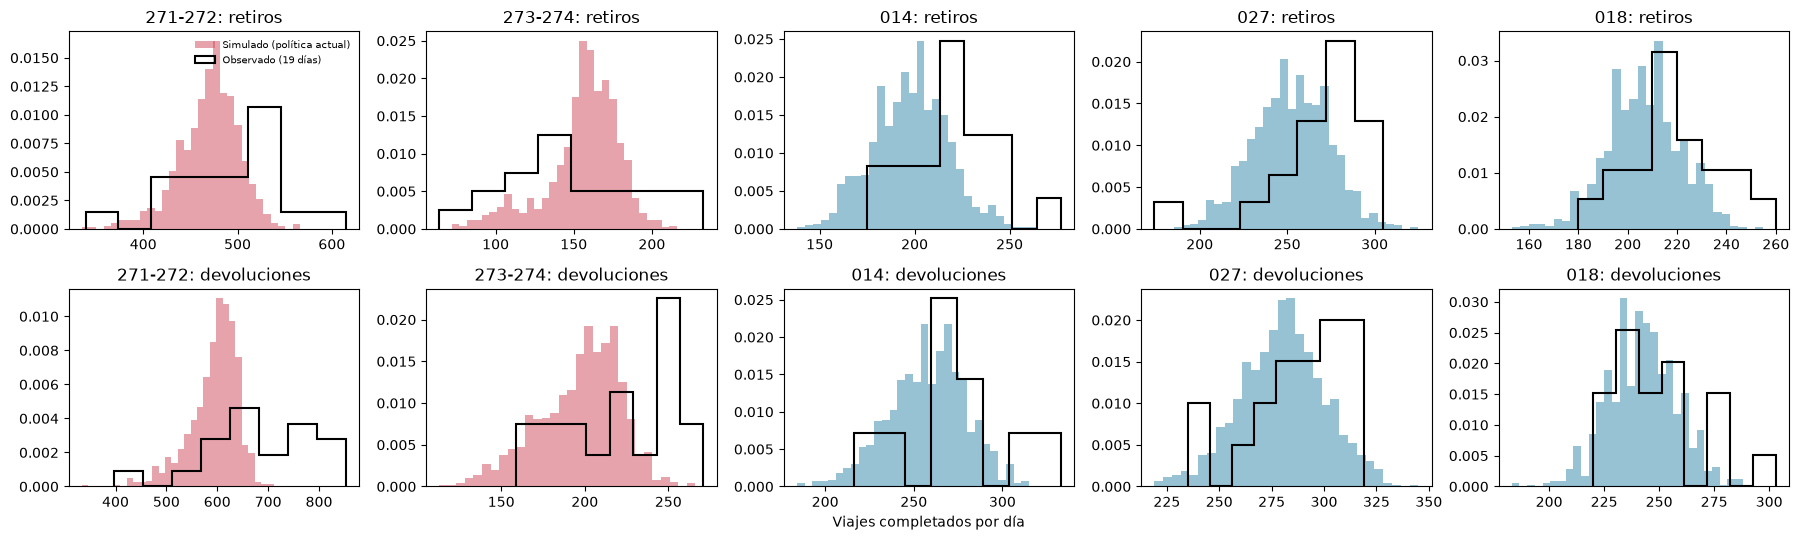

(7 s)


,estación,proceso,obs. media,sim. media,obs. desv.,sim. desv.,obs. dentro de P5–P95 sim.
0,271-272,retiros,491.2,469.6,61.1,31.8,53%
1,271-272,devoluciones,678.1,593.9,111.9,46.8,26%
2,273-274,retiros,150.2,155.9,45.2,23.7,63%
3,273-274,devoluciones,221.1,197.2,34.7,24.7,53%
4,014,retiros,218.6,197.6,24.9,19.7,63%
5,014,devoluciones,272.7,257.7,31.5,21.7,74%
6,027,retiros,268.2,252.0,31.0,21.7,74%
7,027,devoluciones,287.8,280.1,24.2,20.3,79%
8,018,retiros,219.4,206.3,19.1,14.9,74%
9,018,devoluciones,250.0,242.0,20.9,15.6,79%


In [5]:
t0 = time.time()
base_actual = simular("actual", N_SIM, f=1.0, cv=CV, semilla=2)
filas = []
fig, ax = plt.subplots(2, 5, figsize=(18, 5.5))
for i, est in enumerate(ORDEN):
    for j, (nombre, obs, col) in enumerate([("retiros", obs_ret[est], 2), ("devoluciones", obs_dev[est], 3)]):
        sim = base_actual[:, i, col]
        a = ax[j, i]
        a.hist(sim, bins=30, density=True, color=COLORES[SUBRED[est]], alpha=0.5, label="Simulado (política actual)")
        a.hist(obs, bins=8, density=True, histtype="step", color="black", lw=1.5, label="Observado (19 días)")
        a.set_title(f"{est}: {nombre}")
        filas.append({"estación": est, "proceso": nombre, "obs. media": obs.mean(), "sim. media": sim.mean(),
                      "obs. desv.": obs.std(ddof=1), "sim. desv.": sim.std(ddof=1),
                      "obs. dentro de P5–P95 sim.": f"{((obs >= np.percentile(sim, 5)) & (obs <= np.percentile(sim, 95))).mean():.0%}"})
ax[0, 0].legend(frameon=False, fontsize=7); ax[1, 2].set_xlabel("Viajes completados por día")
fig.tight_layout(); fig.savefig(DIR_FIG / "sim_validacion_datos.png", dpi=150, bbox_inches="tight"); plt.show()
val_d = pd.DataFrame(filas)
val_d.round(1).to_csv(DIR_TABLAS / "sim_validacion_datos.csv", index=False)
print(f"({time.time() - t0:.0f} s)")
val_d.round(1)

**Resultados**

- Los promedios se parecen: en Reforma el simulador queda entre 3 % y 10 % abajo, y en la 271-272 da 470 retiros contra 491.
- El error más grande está en las devoluciones de la 271-272: 594 contra 678. Es el mismo que se vio en `camion.ipynb`: el camión real vacía la estación según lo que ve, y aquí se usa su promedio.
- La variación entre días queda más chica que la real en Buenavista (desviación de 47 contra 112 en devoluciones de la 271-272). Parte de esa variación viene de que el camión trabaja distinto cada día, y eso no está en el simulador.
- El simulador es confiable para comparar políticas en promedio. Su variación entre días se queda corta, así que los P95 de la sección 4 son optimistas.

## 3. Escenarios de demanda

Igual que en `eda_b.ipynb`: para cada mes, $f_m$ = mediana de retiros diarios de la subred en días hábiles / la de septiembre 2026. Se definen tres escenarios:

- baja: el mes con menor factor;
- base: septiembre 2026 ($f = 1$), el mes con el que se diseñó la propuesta;
- alta: el mes con mayor factor.

Cada mes se asigna al escenario más cercano. La probabilidad de cada escenario es la fracción de meses que le tocan y se usa para el valor esperado.

In [6]:
cols = ["fecha", "mes", "es_habil", "en_horario", "retiro_subred"]
d12 = pd.read_parquet("data/clean/trips_12m.parquet", columns=cols)
d12 = d12[d12.es_habil & d12.en_horario & d12.retiro_subred]
mediana = d12.groupby(["mes", "fecha"], observed=True).size().groupby("mes", observed=True).median()
del d12
factores = (mediana / mediana["2026-09"]).rename("factor").to_frame()
factores.index = factores.index.astype(str)

ESC = {"baja": factores.factor.min(), "base": 1.0, "alta": factores.factor.max()}
factores["escenario"] = [min(ESC, key=lambda s: abs(ESC[s] - f)) for f in factores.factor]
PROB = factores.escenario.value_counts(normalize=True).reindex(list(ESC)).fillna(0)
factores.round(3).to_csv(DIR_TABLAS / "escenarios.csv")
display(pd.DataFrame({"factor": ESC, "meses": factores.groupby("escenario").size().reindex(list(ESC)),
                      "probabilidad": PROB}).round(3))
factores.round(3).T

,factor,meses,probabilidad
baja,0.971,2,0.154
base,1.000,6,0.462
alta,1.124,5,0.385


mes,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
factor,1.114,1.124,1.1,0.971,1.017,1.096,1.099,1.019,1.027,1.045,1.03,0.985,1.0
escenario,alta,alta,alta,baja,base,alta,alta,base,base,base,base,baja,base


**Resultados**

- Los factores van de 0.97 (diciembre 2025) a 1.12 (octubre 2025): septiembre 2026 está en la parte baja del año.
- Probabilidades: baja 2 de 13 meses (0.15), base 6 de 13 (0.46) y alta 5 de 13 (0.38).

## 4. Evaluación por escenario

Para cada alternativa y escenario se simulan 1,000 días con variación entre días. Se reporta:
- rechazos promedio por día en la subred (con su IC de 95 %);
- P95 de los rechazos (un día malo);
- % de la demanda atendida;
- bicis que mueve el camión.

Las políticas no se ajustan al escenario: el camión actual mueve lo mismo y la propuesta usa el plan diseñado para septiembre. Así se prueba si la propuesta aguanta en meses de demanda distinta.

(52 s)


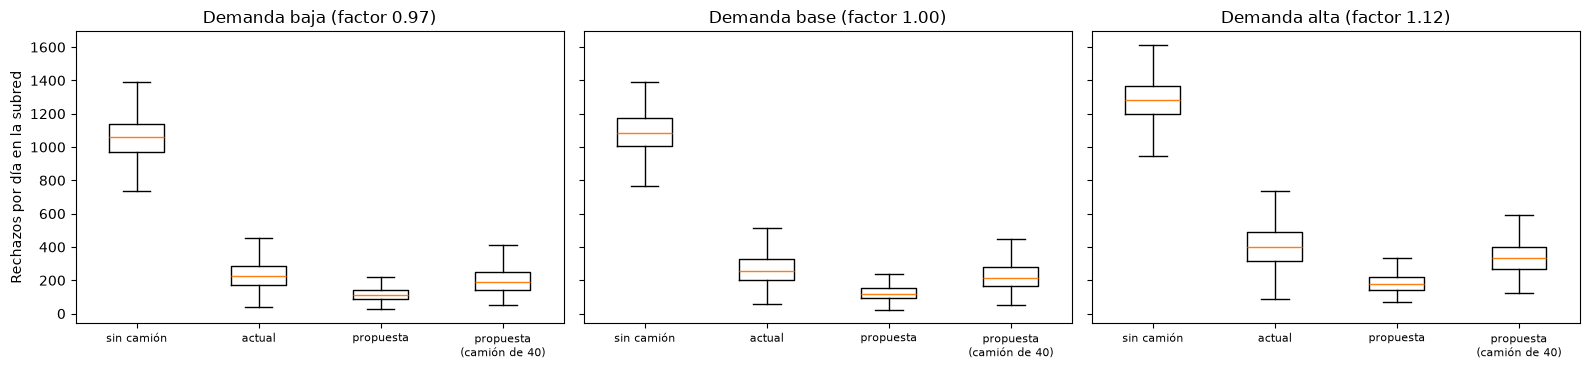

escenario,baja,base,alta
política,,,
sin camión,1056.4,1092.2,1286.5
actual,232.7,270.6,410.9
propuesta,115.3,126.4,187.7
propuesta (camión de 40),201.6,226.2,339.0


In [7]:
t0 = time.time()
res = {}
for e_i, (esc, f) in enumerate(ESC.items()):
    for p_i, politica in enumerate(POLITICAS):
        if esc == "base" and politica == "actual":
            res[(politica, esc)] = base_actual                     # ya simulada en la validación
        else:
            res[(politica, esc)] = simular(politica, N_SIM, f=f, cv=CV, semilla=100 + 10 * e_i + p_i,
                                           capacidad=CAPACIDAD.get(politica))
print(f"({time.time() - t0:.0f} s)")

filas = []
for (politica, esc), s in res.items():
    rech = (s[:, :, 0] + s[:, :, 1]).sum(1)                         # rechazos de la subred por día
    hechos = (s[:, :, 2] + s[:, :, 3]).sum(1)
    filas.append({"política": politica, "escenario": esc, "rechazos (media)": rech.mean(),
                  "IC 95 %": 1.96 * rech.std(ddof=1) / np.sqrt(len(rech)), "rechazos P95": np.percentile(rech, 95),
                  "% demanda atendida": 100 * hechos.sum() / (hechos.sum() + rech.sum()),
                  "bicis movidas": (s[:, :, 4] + s[:, :, 5]).sum(1).mean()})
evaluacion = pd.DataFrame(filas)
evaluacion.round(1).to_csv(DIR_TABLAS / "sim_escenarios.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for a, esc in zip(ax, ESC):
    datos = [(res[(p, esc)][:, :, 0] + res[(p, esc)][:, :, 1]).sum(1) for p in POLITICAS]
    a.boxplot(datos, showfliers=False)
    a.set_xticks(range(1, len(POLITICAS) + 1)); a.set_xticklabels(["sin camión", "actual", "propuesta", "propuesta\n(camión de 40)"], fontsize=8)
    a.set_title(f"Demanda {esc} (factor {ESC[esc]:.2f})")
ax[0].set_ylabel("Rechazos por día en la subred")
fig.tight_layout(); fig.savefig(DIR_FIG / "sim_escenarios.png", dpi=150, bbox_inches="tight"); plt.show()
evaluacion.pivot(index="política", columns="escenario", values="rechazos (media)").reindex(index=POLITICAS, columns=list(ESC)).round(1)

**Resultados**

- En los tres escenarios la propuesta tiene menos de la mitad de los rechazos de la política actual: 115 contra 233 (baja), 126 contra 271 (base) y 188 contra 411 (alta).
- También es más estable en los días malos. En el escenario alto el P95 es 304 contra 647 de la política actual.
- Con camión de 40, la propuesta sigue ganándole a la política actual en todos los escenarios, por menos (202, 226 y 339).
- Con demanda alta la propuesta mueve más bicis que hoy (1,126 contra 1,006), porque deja las estaciones en un nivel fijo y la demanda las aleja más. En baja y base mueve lo mismo o menos.
- Con variación entre días todos los rechazos suben frente a Kolmogorov: la política actual pasa de 207 a 271 en el escenario base y la propuesta de 103 a 126.

## 5. Criterios de decisión

Se comparan las tres alternativas reales (sin camión no es una opción). La matriz de costos son los rechazos esperados por día en cada escenario; en todos los criterios, menor es mejor.

- **Valor esperado:** promedio ponderado por la probabilidad de cada escenario.
- **Laplace:** promedio simple de los escenarios (todos igual de probables).
- **Wald (pesimista):** el peor escenario de cada alternativa; se elige la de menor peor caso.
- **Hurwicz:** $\alpha \cdot \text{mejor} + (1 - \alpha) \cdot \text{peor}$, con $\alpha = 0.5$.
- **Savage:** el arrepentimiento en cada escenario es cuánto peor está una alternativa que la mejor de ese escenario; se elige la de menor arrepentimiento máximo.

In [8]:
ALTERNATIVAS = ["actual", "propuesta", "propuesta (camión de 40)"]      # "sin camión" no es una opción real
M = evaluacion.pivot(index="política", columns="escenario", values="rechazos (media)").reindex(index=ALTERNATIVAS, columns=list(ESC))
ALFA = 0.5                                              # coeficiente de optimismo de Hurwicz

arrep = M - M.min()                                     # arrepentimiento: cuánto peor que la mejor en ese escenario
criterios = pd.DataFrame({
    "Valor esperado": M @ PROB,
    "Laplace": M.mean(axis=1),
    "Wald (peor caso)": M.max(axis=1),
    f"Hurwicz (α = {ALFA})": ALFA * M.min(axis=1) + (1 - ALFA) * M.max(axis=1),
    "Savage (máx. arrepentimiento)": arrep.max(axis=1),
})
criterios.round(1).to_csv(DIR_TABLAS / "sim_criterios.csv")
display(M.round(1).rename_axis(columns="rechazos esperados por día"))
display(arrep.round(1).rename_axis(columns="arrepentimiento"))
print("Elegida por cada criterio (menor es mejor):")
print(criterios.idxmin().to_string())
criterios.round(1)

rechazos esperados por día,baja,base,alta
política,,,
actual,232.7,270.6,410.9
propuesta,115.3,126.4,187.7
propuesta (camión de 40),201.6,226.2,339.0


arrepentimiento,baja,base,alta
política,,,
actual,117.4,144.2,223.3
propuesta,0.0,0.0,0.0
propuesta (camión de 40),86.2,99.9,151.4


Elegida por cada criterio (menor es mejor):
Valor esperado                   propuesta
Laplace                          propuesta
Wald (peor caso)                 propuesta
Hurwicz (α = 0.5)                propuesta
Savage (máx. arrepentimiento)    propuesta


,Valor esperado,Laplace,Wald (peor caso),Hurwicz (α = 0.5),Savage (máx. arrepentimiento)
política,,,,,
actual,318.7,304.7,410.9,321.8,223.3
propuesta,148.3,143.1,187.7,151.5,0.0
propuesta (camión de 40),265.8,255.6,339.0,270.3,151.4


**Resultados**

- Los cinco criterios eligen la propuesta. Su valor esperado es de 148 rechazos por día, contra 319 de la política actual y 266 de la propuesta con camión de 40.
- Gana en los tres escenarios, así que domina a las otras dos alternativas y no depende del criterio ni de $\alpha$. Su arrepentimiento es 0 en todos los escenarios.
- Si el camión solo carga 40 bicis, la propuesta sigue siendo mejor que la política actual con todos los criterios, pero la ventaja baja a unos 50 rechazos por día.

## 6. Conclusión y límites

- Con los criterios del curso, la propuesta de `camion.ipynb` es mejor que la estrategia asignada (política actual) en los tres escenarios. Reduce los rechazos a la mitad o menos, sin mover más bicis salvo en demanda alta.
- La ventaja depende de la capacidad del camión: con 40 bicis por visita se mantiene, y con menos hay que revisarla (en `camion.ipynb`, con 20 o 30 bicis la propuesta pierde contra la política actual).
- El simulador reproduce Kolmogorov y los promedios observados, pero subestima la variación entre días en Buenavista y modela el camión actual con su promedio. Por eso la ventaja de la propuesta puede ser algo menor en la realidad.
- Los escenarios solo escalan la demanda; no cambian la forma del día (en `modelo.ipynb`, sección 3.3, la forma se mantiene entre meses).